# 05 · Predictive Model

**CRISP-DM phase 4 (predictive track) and phase 5 (evaluation).**

Goal: predict `stability_months` **at production time** from the sensor readings, with
- a measure of **confidence** for each prediction (prediction interval), and
- an **explanation** of what drives each prediction (SHAP).

Principles: compare several candidates on the **same temporal split**, start from the simplest, keep complexity only if it pays off.

In [1]:
import sys
import time
from pathlib import Path

# A globally installed pyspark (unrelated to this project) breaks `import shap` on Windows.
# shap does not need it: block the import. Not needed in a clean virtual environment.
sys.modules["pyspark"] = None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, precision_score, r2_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import SENSORS, load_clean, load_config

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
SEED = load_config()["seed"]
TARGET = "stability_months"
AFFECTED = ["P04-R03", "P04-R07", "P04-R08"]

df = load_clean()
df.shape

(253856, 15)

## 1. Features and validation design
**Features: the 7 sensor readings only.**
- Excluded `purity_grade`, `oxidation_risk_flag` → derived from the target (leakage).
- Excluded `date` → a future batch has a date never seen in training; it would only memorise the past.
- Excluded `plant` / `reactor_id` → the root-cause analysis showed plant differences are explained by sensors; a reactor ID would memorise each reactor's history instead of learning the process. (Tested below: adding plant does not help.)
- Missing sensor values are left as `NaN`: gradient boosting handles them natively; the linear models impute the median **learned on the training set only**.

**Temporal split**: train on batches before 2023-06-08, test on the last 3 weeks — the model is evaluated on the *future*, as it would be used.

In [2]:
SPLIT = pd.Timestamp("2023-06-08")
train, test = df[df["date"] < SPLIT], df[df["date"] >= SPLIT]
X_train, y_train = train[SENSORS], train[TARGET]
X_test, y_test = test[SENSORS], test[TARGET]
print(f"train: {len(train):,} batches ({train['date'].min().date()} -> {train['date'].max().date()})")
print(f"test : {len(test):,} batches ({test['date'].min().date()} -> {test['date'].max().date()}) = {len(test) / len(df):.0%}")

train: 191,543 batches (2023-04-01 -> 2023-06-07)
test : 62,313 batches (2023-06-08 -> 2023-06-29) = 25%


## 2. Candidate models
| Candidate | Why |
|---|---|
| Global mean | Floor: "predict the average" |
| Mean per reactor | What Quality could do today without sensors |
| Linear regression | Simple, interpretable reference |
| Linear + squared terms | Root-cause analysis found U-shapes (pH, pressure) |
| Random forest | Tree ensemble, captures non-linearities |
| Gradient boosting (`HistGradientBoostingRegressor`) | Tree ensemble, fast, handles missing values natively |

In [3]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R²": r2_score(y_true, y_pred)}

reactor_mean = train.groupby("reactor_id", observed=True)[TARGET].mean()
results, preds = {}, {}

preds["Global mean"] = np.full(len(test), y_train.mean())
preds["Mean per reactor"] = test["reactor_id"].map(reactor_mean).astype(float).values

models = {
    "Linear regression": make_pipeline(SimpleImputer(strategy="median"), LinearRegression()),
    "Linear + squared terms": make_pipeline(SimpleImputer(strategy="median"),
                                            PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=SEED),
}
fit_seconds = {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_seconds[name] = time.time() - t0
    preds[name] = model.predict(X_test)

comparison = pd.DataFrame({name: metrics(y_test, p) for name, p in preds.items()}).T
comparison["fit time (s)"] = pd.Series(fit_seconds)
comparison.round(3)

,MAE,RMSE,R²,fit time (s)
Global mean,1.738,2.093,-0.005,NaN
Mean per reactor,1.628,1.949,0.128,NaN
Linear regression,1.065,1.333,0.592,0.209
Linear + squared terms,0.789,0.999,0.771,0.464
Random forest,0.741,0.962,0.788,66.463
Gradient boosting,0.728,0.941,0.797,0.952


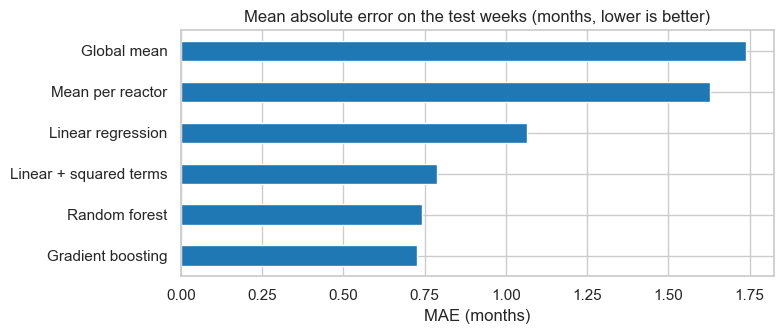

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
comparison["MAE"].sort_values().plot(kind="barh", ax=ax, color="tab:blue")
ax.set(title="Mean absolute error on the test weeks (months, lower is better)", xlabel="MAE (months)")
plt.tight_layout(); plt.show()

- Sensors carry a lot of information: from MAE ≈ 1.7 months (mean) to ≈ 0.73 (gradient boosting); R² from 0 to ≈ 0.80.
- Knowing the reactor alone helps little (R² ≈ 0.13).
- The plain linear model misses the non-linearities; adding squared terms (the U-shapes found in the root-cause analysis) closes most of the gap.
- **Gradient boosting** is the best, slightly ahead of random forest, and far faster to train (≈1 s vs ≈1 min) → **chosen model**.

In [5]:
# Experiment: does adding the plant help? (expected: no, from the root-cause analysis)
Xp_train = pd.get_dummies(train[SENSORS + ["plant"]], columns=["plant"])
Xp_test = pd.get_dummies(test[SENSORS + ["plant"]], columns=["plant"])
gb_plant = HistGradientBoostingRegressor(random_state=SEED).fit(Xp_train, y_train)
print(f"R² sensors only: {r2_score(y_test, preds['Gradient boosting']):.4f} | sensors + plant: {r2_score(y_test, gb_plant.predict(Xp_test)):.4f}")

R² sensors only: 0.7969 | sensors + plant: 0.7995


Adding the plant does not improve the model → keep sensors only (simpler and more general).

## 3. Error analysis of the chosen model

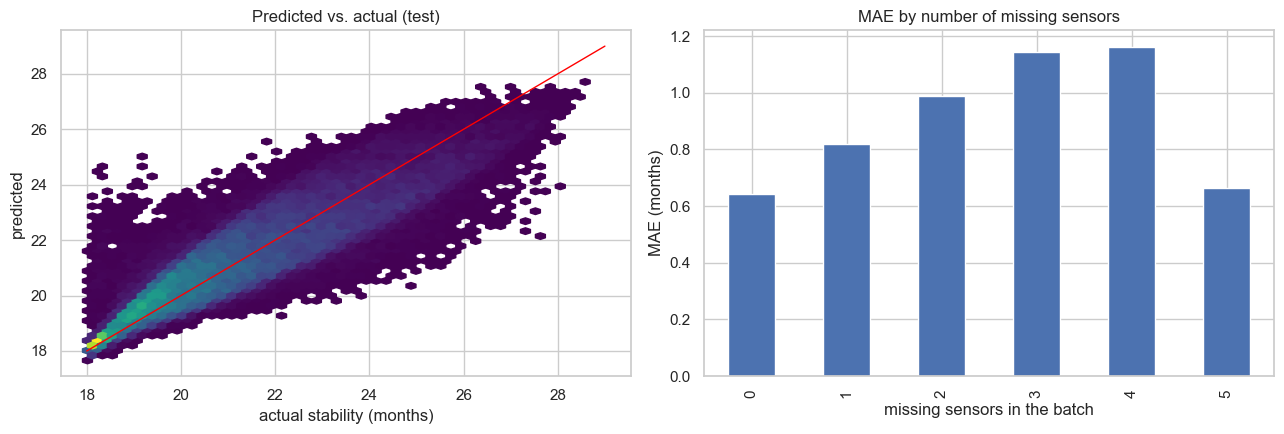

,mean,count
0,0.641,37279
1,0.818,19845
2,0.988,4539
3,1.145,600
4,1.162,49
5,0.664,1


In [6]:
model = models["Gradient boosting"]
pred = preds["Gradient boosting"]
abs_err = np.abs(y_test.values - pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hexbin(y_test, pred, gridsize=50, cmap="viridis", mincnt=1)
axes[0].plot([18, 29], [18, 29], c="red", lw=1)
axes[0].set(title="Predicted vs. actual (test)", xlabel="actual stability (months)", ylabel="predicted")
n_missing = X_test.isna().sum(axis=1)
err_by_missing = pd.Series(abs_err).groupby(n_missing.values).agg(["mean", "count"])
err_by_missing["mean"].plot(kind="bar", ax=axes[1])
axes[1].set(title="MAE by number of missing sensors", xlabel="missing sensors in the batch", ylabel="MAE (months)")
plt.tight_layout(); plt.show()
err_by_missing.round(3)

In [7]:
torque_missing = X_test["mixing_torque_nm"].isna().values
aff = test["reactor_id"].isin(AFFECTED).values
print(f"MAE | all sensors present: {abs_err[X_test.notna().all(axis=1).values].mean():.2f}"
      f" | torque missing: {abs_err[torque_missing].mean():.2f}")
print(f"Affected reactors (P04-R03/R07/R08): MAE {abs_err[aff].mean():.2f} | "
      f"mean predicted {pred[aff].mean():.2f} vs actual {y_test.values[aff].mean():.2f}")

MAE | all sensors present: 0.64 | torque missing: 1.46
Affected reactors (P04-R03/R07/R08): MAE 0.41 | mean predicted 18.84 vs actual 18.61


- Errors grow when sensors are missing — above all when **torque** (the strongest driver) is missing.
- The degraded reactors are predicted well: the model recognises the low-torque regime.

## 4. Confidence: prediction intervals
Two extra gradient-boosting models predict the **5th and 95th percentiles** (quantile loss) → a **90% interval** for each batch:
*"this batch will last between X and Y months, with 90% confidence"*.
An interval is only useful if it is **calibrated**: on the test weeks ≈ 90% of batches should fall inside it.

In [8]:
q_low = HistGradientBoostingRegressor(loss="quantile", quantile=0.05, random_state=SEED).fit(X_train, y_train)
q_high = HistGradientBoostingRegressor(loss="quantile", quantile=0.95, random_state=SEED).fit(X_train, y_train)
low, high = q_low.predict(X_test), q_high.predict(X_test)
inside = (y_test.values >= low) & (y_test.values <= high)
width = high - low

complete = X_test.notna().all(axis=1).values
pd.DataFrame({
    "coverage (target 90%)": [inside.mean(), inside[complete].mean(), inside[~complete].mean(), inside[torque_missing].mean()],
    "mean width (months)": [width.mean(), width[complete].mean(), width[~complete].mean(), width[torque_missing].mean()],
}, index=["all test batches", "all sensors present", "some sensor missing", "torque missing"]).round(3)

,coverage (target 90%),mean width (months)
all test batches,0.889,2.758
all sensors present,0.891,2.413
some sensor missing,0.885,3.272
torque missing,0.858,5.339


- Coverage ≈ 89% for a 90% target → **well calibrated** (a bit lower, ≈ 86%, when torque is missing).
- The interval **adapts to the information available**: ≈ 2.4 months wide when all sensors are present, ≈ 5.3 months when torque is missing.
  The model "knows when it doesn't know" — useful to decide which batches still need a lab test.

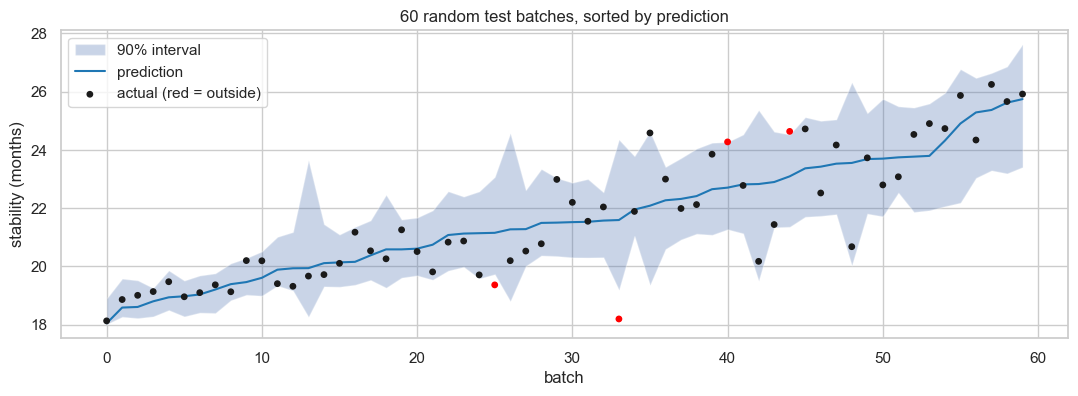

In [9]:
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(test), 60, replace=False))
order = idx[np.argsort(pred[idx])]
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(order))
ax.fill_between(x, low[order], high[order], alpha=0.3, label="90% interval")
ax.plot(x, pred[order], c="tab:blue", label="prediction")
ax.scatter(x, y_test.values[order], c=np.where(inside[order], "k", "red"), s=15, zorder=3, label="actual (red = outside)")
ax.set(title="60 random test batches, sorted by prediction", xlabel="batch", ylabel="stability (months)")
ax.legend(); plt.show()

## 5. Business use: flagging batches at risk
`oxidation_risk_flag` = stability < 21 months. Two possible rules, from the same model:

In [10]:
actual_risk = y_test.values < 21
rules = {"point prediction < 21": pred < 21,
         "lower bound of interval < 21 (cautious)": low < 21}
pd.DataFrame({name: {"recall (risky batches caught)": recall_score(actual_risk, flag),
                     "precision (flags that are right)": precision_score(actual_risk, flag),
                     "share of batches flagged": flag.mean()}
              for name, flag in rules.items()}).T.round(3)

,recall (risky batches caught),precision (flags that are right),share of batches flagged
point prediction < 21,0.818,0.872,0.451
lower bound of interval < 21 (cautious),0.996,0.643,0.745


- **Point prediction**: catches ≈ 82% of risky batches, and ≈ 87% of its alarms are right.
- **Cautious rule** (flag if the batch *could* be below 21): catches ≈ 99.6% of risky batches, at the cost of more false alarms.
The choice is a business trade-off (cost of a missed bad batch vs. cost of an extra lab test).

## 6. Explainability with SHAP
SHAP splits each prediction into contributions of each sensor (in months), relative to the average prediction.
Computed on a random sample of 2,000 test batches.

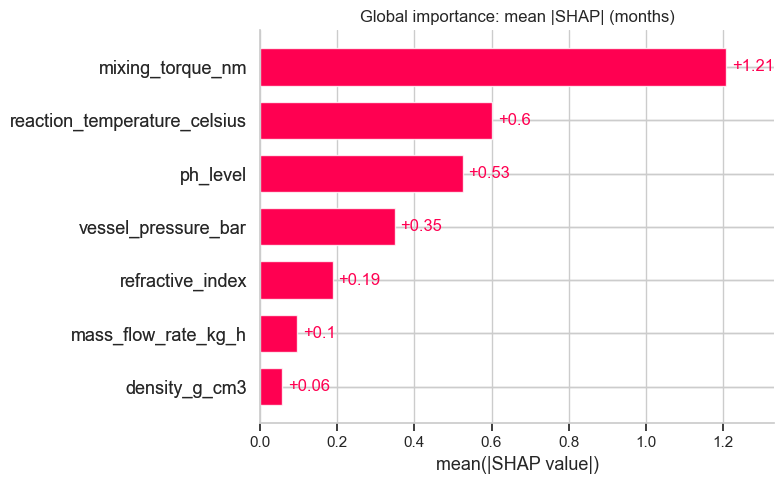

In [11]:
explainer = shap.TreeExplainer(model)
X_shap = X_test.sample(2000, random_state=SEED)
shap_values = explainer(X_shap)
shap.plots.bar(shap_values, show=False)
plt.title("Global importance: mean |SHAP| (months)"); plt.tight_layout(); plt.show()

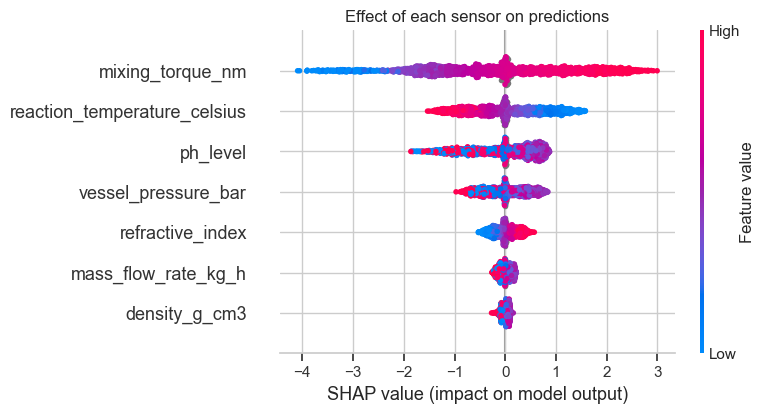

In [12]:
shap.plots.beeswarm(shap_values, show=False)
plt.title("Effect of each sensor on predictions"); plt.tight_layout(); plt.show()

Global importance matches the root-cause analysis: **torque ≫ temperature ≈ pH > pressure**, the rest small.
In the beeswarm: high torque (red) → longer stability; high temperature → shorter; pH and pressure have effects in both directions (U-shape).

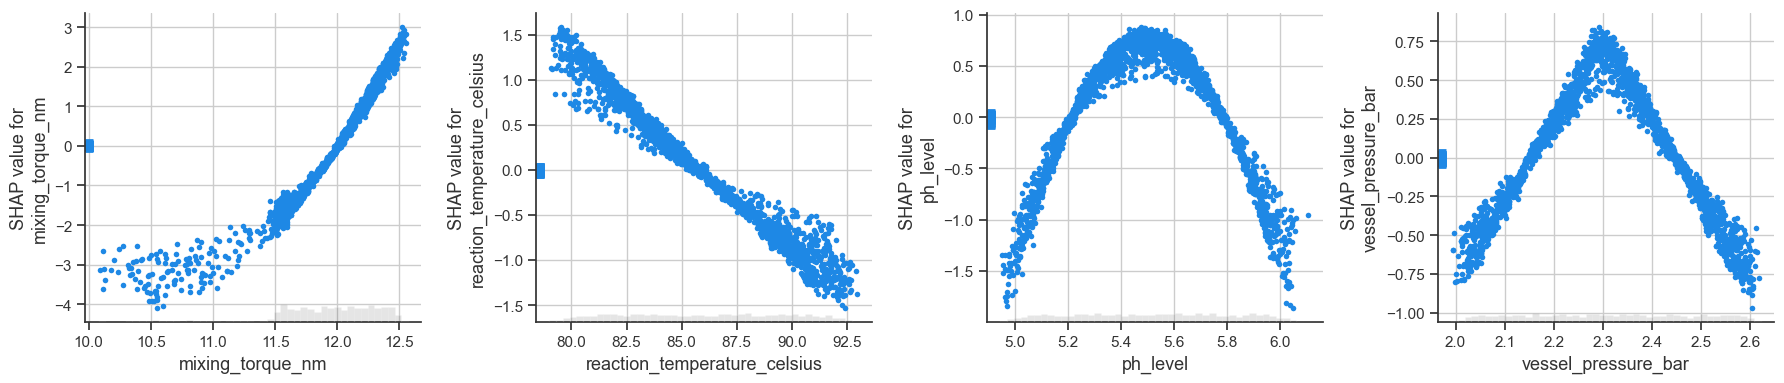

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["mixing_torque_nm", "reaction_temperature_celsius", "ph_level", "vessel_pressure_bar"]):
    shap.plots.scatter(shap_values[:, c], ax=ax, show=False)
plt.tight_layout(); plt.show()

The dependence plots recover what the root-cause analysis found *without being told*: torque increasing (flattening at low torque),
temperature decreasing, and **optima for pH (≈ 5.5) and pressure (≈ 2.3 bar)**. Two independent methods agree → more confidence in the conclusions.

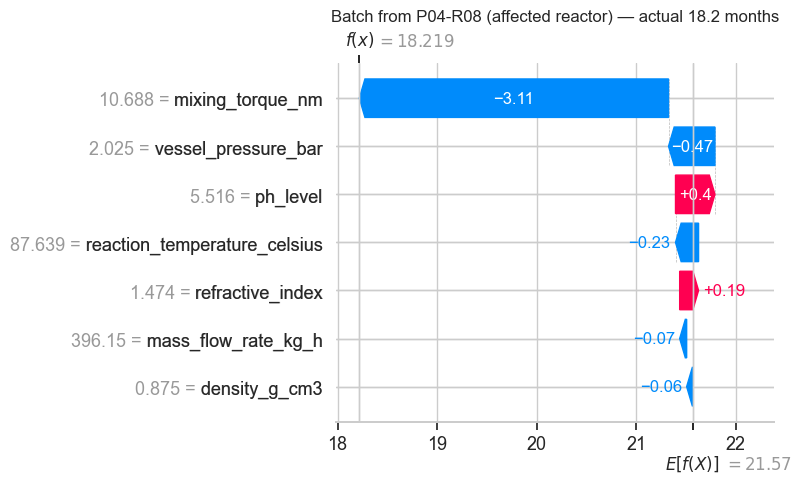

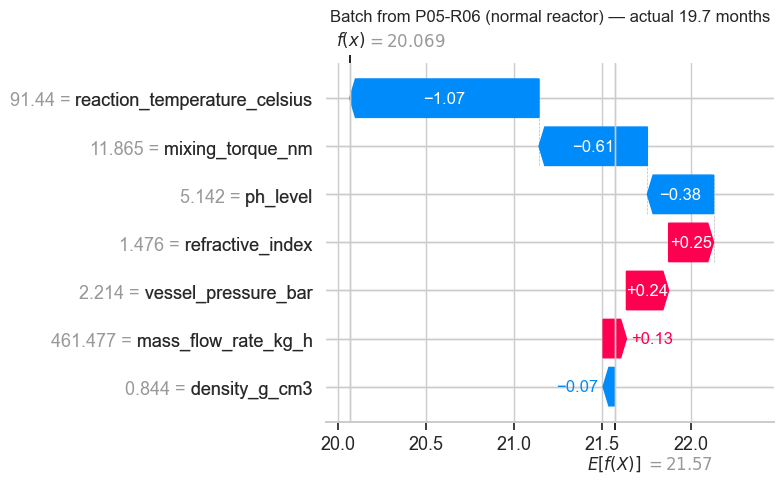

In [14]:
# One batch from an affected reactor vs. one normal batch, both with all sensors present
full = X_test.notna().all(axis=1)
i_aff = X_test[full & test["reactor_id"].isin(AFFECTED)].index[0]
i_ok = X_test[full & ~test["reactor_id"].isin(AFFECTED)].index[0]
for label, i in [("affected reactor", i_aff), ("normal reactor", i_ok)]:
    sv = explainer(X_test.loc[[i]])
    shap.plots.waterfall(sv[0], show=False)
    plt.title(f"Batch from {test.loc[i, 'reactor_id']} ({label}) — actual {test.loc[i, TARGET]:.1f} months")
    plt.tight_layout(); plt.show()

Per-batch explanation: for the affected reactor, low torque alone pulls the prediction down by several months — exactly the message for the plant engineer.

## 7. Robustness: what if the model had been trained before the incident?
Train only on batches before 2023-05-08 (the model never sees the low-torque regime) and predict the same test weeks.

In [15]:
early = df[df["date"] < "2023-05-08"]
gb_early = HistGradientBoostingRegressor(random_state=SEED).fit(early[SENSORS], early[TARGET])
p_early = gb_early.predict(X_test)
pd.DataFrame({
    "MAE affected reactors": [abs_err[aff].mean(), np.abs(y_test.values - p_early)[aff].mean()],
    "MAE other reactors": [abs_err[~aff].mean(), np.abs(y_test.values - p_early)[~aff].mean()],
}, index=["trained until 06-07 (main model)", "trained until 05-07 (before incident)"]).round(3)

,MAE affected reactors,MAE other reactors
trained until 06-07 (main model),0.406,0.758
trained until 05-07 (before incident),1.247,0.760


A model that never saw low torque **cannot extrapolate**: on the affected reactors its error triples (trees predict the edge of what they have seen).
→ In deployment: **monitor** sensors for values outside the training range and **retrain** as new lab results arrive.

## 8. Summary
| Item | Result |
|---|---|
| Chosen model | Gradient boosting on the 7 sensors |
| Accuracy (test = last 3 weeks) | MAE ≈ 0.73 months, R² ≈ 0.80 (global mean: MAE ≈ 1.74) |
| Confidence | 90% intervals, coverage ≈ 89%, ≈ 2.4 months wide with all sensors; wider when sensors are missing |
| Risk flag (< 21 months) | Recall ≈ 82% / precision ≈ 87% (point); recall ≈ 99.6% with the cautious rule |
| Explanations | SHAP: torque ≫ temperature ≈ pH > pressure; same shapes as the root-cause analysis |
| Limitation | No extrapolation outside the training range → monitoring and retraining needed |